# MetricSuite 1 -- Getting started

A `MetricSuite` collects the outputs of a study (one number, or one curve, per
method, subject, run...), then tests, estimates and plots them. This first tutorial
runs the whole loop once, on fake data:

- **Part 1 -- Register** outputs, tagged with the labels you'll group and pair by.
- **Part 2 -- Test** two methods against each other and read the result.
- **Part 3 -- Plot** the result.
- **Part 4 -- Save, load, verify**, and pool several suites.

One idea runs through the whole package: **the suite holds the data and computes; a
result holds the output and every setting that produced it.** Results never point
back at the suite and nothing is cached, so a result can be saved, shared and
reloaded on its own, and `suite.verify(result)` tells you whether it still matches
the data.

The other tutorials go deeper, one topic each:

| # | Tutorial | Topic |
|---|---|---|
| 1 | Getting started | this one |
| 2 | Data plots | looking at the data before testing |
| 3 | Choosing a test | paired vs independent, units, corrections |
| 4 | Effect sizes and estimates | how large is a difference, non-inferiority, ties |
| 5 | Binary outcomes | proportions, McNemar, Newcombe |
| 6 | Bootstrap | bootstrap intervals and tests, draws made upstream |
| 7 | Curves | windows, cluster permutation, difference curves |
| 8 | Recipe | a full revision plan, request by request |

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite
from mindmap.metric.results import PairwiseResult

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948"}

## 🧪 - Part 1: Registering outputs

### The fake study

Three source-imaging methods (`wCSET`, `CSET`, `dSPM`) localize simulated spikes in
16 patients. Each patient is simulated 3 times (3 noise realisations, `run`), and
every simulation gives two outputs:

- `loc_error_mm`, the localization error -- lower is better;
- `correlation` between the true and estimated sources -- higher is better.

Each patient has their own difficulty, shared by every method. That's what makes a
*paired* comparison (method A vs B **within** each patient) so much more sensitive
than comparing pooled groups.

In [2]:
TRUE_ERROR = {"wCSET": 14.0, "CSET": 16.0, "dSPM": 22.0}   # mm
N_PATIENTS, N_RUNS = 16, 3


def make_study(seed, name="Fake study"):
    rng = np.random.default_rng(seed)
    suite = MetricSuite(name=name)
    for p in range(N_PATIENTS):
        patient = f"P{p:02d}"
        difficulty = rng.normal(0, 4)                       # shared by every method
        for method, mu in TRUE_ERROR.items():
            for run in range(N_RUNS):
                err = max(mu + difficulty + rng.normal(0, 3), 0.5)
                corr = np.clip(0.95 - err / 60 + rng.normal(0, 0.03), -1, 1)
                suite.register("loc_error_mm", err, method=method, patient=patient, run=run)
                suite.register("correlation", corr, method=method, patient=patient, run=run)
    return suite


suite = make_study(seed=0)

### What `register` does

`suite.register(metric, values, **coords)` adds one output:

- `metric` names the outcome (`"loc_error_mm"`);
- `values` is the measurement -- here one number;
- every keyword is a label (`method=`, `patient=`, `run=`). There's no special
  "group" argument: any label can later be used to group, pair or filter.

`describe()` lists what's in the suite -- each metric, and the labels it carries:

In [3]:
suite.describe()

,Metric,Coord,Kind,N unique,Detail
0,correlation,method,categorical,3,"CSET, dSPM, wCSET"
1,correlation,patient,categorical,16,"P00, P01, P02, P03, P04, P05, P06, P07, ... (+..."
2,correlation,run,numerical,3,"[0, 2]"
3,loc_error_mm,method,categorical,3,"CSET, dSPM, wCSET"
4,loc_error_mm,patient,categorical,16,"P00, P01, P02, P03, P04, P05, P06, P07, ... (+..."
5,loc_error_mm,run,numerical,3,"[0, 2]"


`to_df()` gives the long table everything else is built on, one row per value.
`filters` keeps only rows matching some labels:

In [4]:
suite.to_df(metrics="loc_error_mm", filters={"patient": "P00"})

,Metric,Value,method,patient,run
0,loc_error_mm,14.106606,wCSET,P00,0
2,loc_error_mm,14.817621,wCSET,P00,1
4,loc_error_mm,15.587706,wCSET,P00,2
6,loc_error_mm,19.344164,CSET,P00,0
8,loc_error_mm,12.706656,CSET,P00,1
10,loc_error_mm,16.626899,CSET,P00,2
12,loc_error_mm,21.846546,dSPM,P00,0
14,loc_error_mm,20.306119,dSPM,P00,1
16,loc_error_mm,21.554020,dSPM,P00,2


`summary()` is a quick sanity check before any plot or test:

In [5]:
suite.summary("loc_error_mm", group_by="method")

,method,mean,std,count
0,CSET,16.738487,5.470208,48
1,dSPM,22.889200,4.644981,48
2,wCSET,15.358552,5.417405,48


### Curves and repeated curves

`values` can also be a curve, with a label per point (here `times`), or a stack of
curves -- one row per repetition, numbered automatically in a `rep` column. Each
point becomes a row of the long table. Curves are the topic of tutorial 7; here is
just the shape:

In [6]:
demo = MetricSuite(name="Curves")
times = np.linspace(0, 0.2, 5)
demo.register("activity", np.sin(10 * times), method="wCSET", patient="P00", times=times)
demo.register("activity", np.random.default_rng(0).normal(size=(2, 5)), method="dSPM", patient="P00", times=times)
demo.to_df()

,Metric,Value,method,patient,times,rep
0,activity,0.000000,wCSET,P00,0.00,NaN
1,activity,0.479426,wCSET,P00,0.05,NaN
2,activity,0.841471,wCSET,P00,0.10,NaN
3,activity,0.997495,wCSET,P00,0.15,NaN
4,activity,0.909297,wCSET,P00,0.20,NaN
5,activity,0.125730,dSPM,P00,0.00,0.0
6,activity,-0.132105,dSPM,P00,0.05,0.0
7,activity,0.640423,dSPM,P00,0.10,0.0
8,activity,0.104900,dSPM,P00,0.15,0.0
9,activity,-0.535669,dSPM,P00,0.20,0.0


## 🔬 - Part 2: A first test

Is `wCSET` more accurate than the two others? `suite.stat.wilcoxon` runs a paired
Wilcoxon signed-rank test for every requested pair:

- `group_by="method"`: the label holding the groups;
- `comparisons`: which pairs. `build_comparisons("wCSET", [...])` makes the usual
  "one reference vs every competitor" list;
- `pairing_col="patient"`: the matching unit -- methods are compared patient by
  patient;
- `unit_col="run"`: the 3 runs of a patient are averaged first, so a patient counts
  once, not 3 times (tutorial 3 explains why this matters).

In [7]:
comparisons = suite.stat.build_comparisons("wCSET", ["CSET", "dSPM"])
comparisons

[('wCSET', 'CSET'), ('wCSET', 'dSPM')]

In [8]:
err = suite.stat.wilcoxon(
    "loc_error_mm", group_by="method", comparisons=comparisons,
    pairing_col="patient", unit_col="run", correction="holm",
)
err

PairwiseResult(metric='loc_error_mm', test='wilcoxon', correction='holm', alpha=0.05, n_comparisons=2)
  wCSET vs CSET: p=0.002686*, rank_biserial=-0.809 [-0.985, -0.456], n=16
  wCSET vs dSPM: p=6.104e-05*, rank_biserial=-1 [-1, -1], n=16

The result is a `PairwiseResult`. Its `table` has one row per pair: the test
statistic, the raw and corrected p-values, and an effect size (here the
rank-biserial correlation `r`, the Wilcoxon test's default -- tutorial 4 covers the
others) **with its 95% confidence interval** (`rank_biserial_ci_low`/`_ci_high`):

In [9]:
err.table

,group_a,group_b,n_pairs,n_zero,n_a,n_b,statistic,p_value,n_eff,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high
0,wCSET,CSET,16,0,16,16,13.0,0.002686,NaN,0.002686,True,-0.808824,-0.985294,-0.455882
1,wCSET,dSPM,16,0,16,16,0.0,0.000031,NaN,0.000061,True,-1.000000,-1.000000,-1.000000


`vs(reference)` is the compact view of "one reference against every competitor".
It orients everything so that **positive means the reference is better**. For an
error, lower is better, so say so with `higher_is_better=False`:

In [10]:
err.vs("wCSET", higher_is_better=False)

,p_value,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,
CSET,0.002686,0.002686,True,0.808824,0.455882,0.985294,0.0,two-sided,16,0
dSPM,0.000031,0.000061,True,1.000000,1.000000,1.000000,0.0,two-sided,16,0


The result also records every setting that produced it -- enough to read or
reproduce it without the suite:

In [11]:
{k: getattr(err, k) for k in ["metric", "test", "group_by", "pairing_col", "unit_col",
                               "effect_sizes", "offset", "alternative", "correction", "data_key"]}

{'metric': 'loc_error_mm',
 'test': 'wilcoxon',
 'group_by': 'method',
 'pairing_col': 'patient',
 'unit_col': 'run',
 'effect_sizes': ('rank_biserial',),
 'offset': 0.0,
 'alternative': 'two-sided',
 'correction': 'holm',
 'data_key': '9f6619bd4811444f'}

## 📊 - Part 3: A first plot

`suite.plot.<view>(result)` draws a result. `group_comparison` shows each method's
values (one point per patient, runs averaged exactly as the test did) with a bracket
per significant pair. `paired_differences` shows what a paired test really looks at:
one difference per patient, with the test's own estimate and its 95% interval.

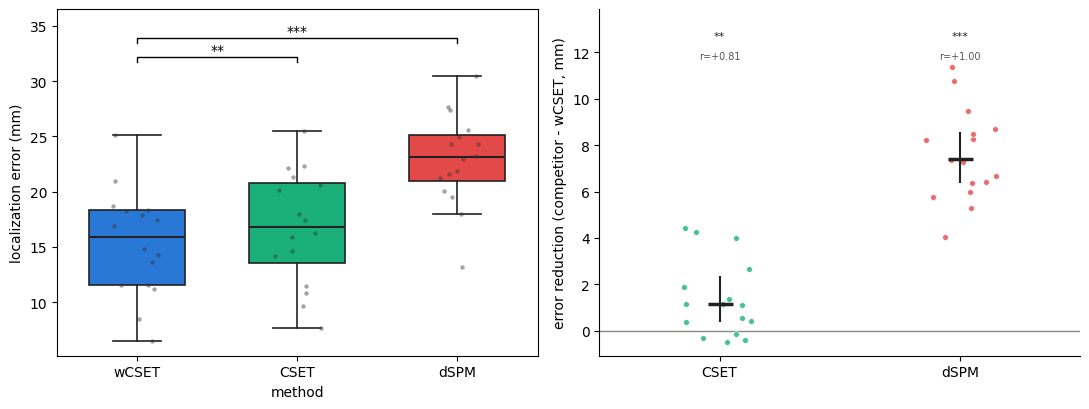

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
suite.plot.group_comparison(err, order=["wCSET", "CSET", "dSPM"], palette=COLORS, ylabel="localization error (mm)", ax=axes[0])
suite.plot.paired_differences(
    err, higher_is_better=False, palette=COLORS, ax=axes[1],
    ylabel="error reduction (competitor - wCSET, mm)",
)
fig.tight_layout()

Every plot returns a `Plot`. It unpacks as `fig, ax` like above, and it also keeps
the numbers it drew in `.data` -- the medians and intervals here are computed by the
suite, not by matplotlib:

In [13]:
p = suite.plot.paired_differences(err, higher_is_better=False)
plt.close(p.fig)
p.data[["method", "n", "center", "low", "high", "annotation"]]

,method,n,center,low,high,annotation
0,CSET,16,1.170767,0.390100,2.344154,** | r=+0.81
1,dSPM,16,7.417122,6.364477,8.578719,*** | r=+1.00


## 💾 - Part 4: Saving, loading, verifying

### The suite and its results are saved separately

`suite.save(folder)` stores the data; `result.save(folder)` stores one result,
with its settings and `data_key`. Nothing else is cached -- every `suite.stat.*`
call computes fresh, and you keep a result by saving it.

In [14]:
workdir = Path(tempfile.mkdtemp())
suite.save(workdir / "study")
err.save(workdir / "error_wilcoxon")

reloaded = MetricSuite.load(workdir / "study")
err_loaded = PairwiseResult.load(workdir / "error_wilcoxon")
err_loaded

MetricSuite successfully saved to folder: /tmp/tmptj_kx4yz/study


PairwiseResult(metric='loc_error_mm', test='wilcoxon', correction='holm', alpha=0.05, n_comparisons=2)
  wCSET vs CSET: p=0.002686*, rank_biserial=-0.809 [-0.985, -0.456], n=16
  wCSET vs dSPM: p=6.104e-05*, rank_biserial=-1 [-1, -1], n=16

A result can be re-corrected later without rerunning the tests:

In [15]:
err_loaded.correct("bonferroni", alpha=0.01).vs("wCSET", higher_is_better=False)[["p_value", "p_corrected", "significant"]]

,p_value,p_corrected,significant
method,,,
CSET,0.002686,0.005371,True
dSPM,0.000031,0.000061,True


### Does this result belong to this suite?

`verify` compares the result's `data_key` -- a fingerprint of the exact rows it was
computed from -- with the suite's current data. The reloaded suite matches; a study
simulated with another seed doesn't:

In [16]:
other = make_study(seed=1, name="Another study")
reloaded.verify(err_loaded), other.verify(err_loaded)

(True, False)

Registering more data for a metric changes its fingerprint, so older results on that
metric stop verifying -- results on other metrics are unaffected:

In [17]:
reloaded.register("loc_error_mm", 12.0, method="wCSET", patient="P16", run=0)
reloaded.verify(err_loaded)

False

Plots and estimates re-read the data behind a result, so they refuse a result that
doesn't match instead of silently drawing other data:

In [18]:
try:
    other.plot.paired_differences(err_loaded)
except ValueError as e:
    print(e)
plt.close("all")

This PairwiseResult (metric='loc_error_mm') was computed from different data than this suite now holds -- another suite, or this one before more data was registered. Recompute it from this suite.


### Pooling batches

`MetricSuite.concat` pools several suites, e.g. one per batch of patients. Results on
a metric that gained rows no longer verify -- recompute them on the pooled data.

In [19]:
batch_2 = MetricSuite(name="Batch 2")
for method, err_mm in [("wCSET", 13.0), ("CSET", 15.5), ("dSPM", 20.0)]:
    batch_2.register("loc_error_mm", err_mm, method=method, patient="P20", run=0)

pooled = MetricSuite.concat([suite, batch_2], name="Pooled")
pooled.summary("loc_error_mm", group_by="method"), pooled.verify(err)

(  method       mean       std  count
 0   CSET  16.713212  5.415818     49
 1   dSPM  22.830236  4.614836     49
 2  wCSET  15.310419  5.371255     49,
 False)

## Wrap-up

- `register(metric, values, **labels)` adds outputs; `describe()`, `to_df()`,
  `summary()` inspect them.
- `suite.stat.<test>(...)` returns a result that describes itself; `vs(reference)`
  orients it so positive means "reference better".
- `suite.plot.<view>(result)` draws it and returns a `Plot` (`fig, ax`, `.data`).
- `suite.save` / `MetricSuite.load` for the data, `result.save` / `<Result>.load`
  for each result, `suite.verify(result)` to check they match.

Next: **tutorial 2** looks at the data before testing it.